<a href="https://colab.research.google.com/github/anajugrzyb/agenda/blob/main/agentes_langchain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**🦜LangChain: automatizando análise de dados com agentes**



##**Aula 1: Respondendo perguntas sobre dados em arquivos CSV**

###**Gerando códigos com LLMs para analisar dados**

In [1]:
!pip install langchain-groq -q
!pip install langchain-experimental -q

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/anajugrzyb/agentes_langchain/refs/heads/main/dados_entregas.csv")
df.head()

,ID_pedido,anos_experiencia_agente,classificacao_agente,latitude_loja,longitude_loja,latitude_entrega,longitude_entrega,data_pedido,hora_pedido,hora_retirada,clima,trafego,veiculo,area,categoria_produto,tempo_entrega
0,ialx566343618,8,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,11:30:00,11:45:00,Ensolarado,Alto,Motocicleta,Urbano,Roupas,120
1,akqg208421122,10,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,19:45:00,19:50:00,Chuvoso,Congestionamento,Scooter,Metropolitano,Eletronicos,165
2,njpu434582536,16,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,08:30:00,08:45:00,Tempestade,Baixo,Motocicleta,Urbano,Esportes,130
3,rjto796129700,8,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,18:00:00,18:10:00,Ensolarado,Medio,Motocicleta,Metropolitano,Cosmeticos,105
4,zguw716275638,11,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,13:30:00,13:45:00,Nublado,Alto,Scooter,Metropolitano,Brinquedos,150


In [4]:
from google.colab import userdata
GROQ_API_KEY = userdata.get('GROQ_API_KEY')

In [5]:
from langchain_groq import ChatGroq

In [6]:
llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    api_key=GROQ_API_KEY,
    temperature=0
)

In [7]:
ai_msg = llm.invoke(
    '''
    Eu tenho um dataframe chamado 'df' com as colunas 'anos_experiencia_agente' e 'tempo_entrega'.
    Escreva o código Python com a biblioteca Pandas para calcular a correlação entre as duas colunas.
    Retorne o Markdown para o trecho de código Python e nada mais.
    '''
)

ai_msg

AIMessage(content='```python\n# Importando a biblioteca pandas\nimport pandas as pd\n\n# Calculando a correlação entre as colunas \'anos_experiencia_agente\' e \'tempo_entrega\'\ncorrelacao = df[\'anos_experiencia_agente\'].corr(df[\'tempo_entrega\'])\n\n# Imprimindo o resultado\nprint("A correlação entre as colunas \'anos_experiencia_agente\' e \'tempo_entrega\' é:", correlacao)\n```', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 100, 'prompt_tokens': 106, 'total_tokens': 206, 'completion_time': 0.191724608, 'completion_tokens_details': None, 'prompt_time': 0.035979271, 'prompt_tokens_details': None, 'queue_time': 0.711540905, 'total_time': 0.227703879}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_ce7bc1685b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019f905e-d9f8-7c00-bc2e-c1c3f5efe2b4-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1

In [8]:
print(ai_msg.content)

```python
# Importando a biblioteca pandas
import pandas as pd

# Calculando a correlação entre as colunas 'anos_experiencia_agente' e 'tempo_entrega'
correlacao = df['anos_experiencia_agente'].corr(df['tempo_entrega'])

# Imprimindo o resultado
print("A correlação entre as colunas 'anos_experiencia_agente' e 'tempo_entrega' é:", correlacao)
```


In [9]:
# Calcular a correlação entre as colunas 'anos_experiencia_agente' e 'tempo_entrega'
correlacao = df['anos_experiencia_agente'].corr(df['tempo_entrega'])

# Imprimir o resultado
print(f"A correlação entre as colunas 'anos_experiencia_agente' e 'tempo_entrega' é: ", correlacao)

A correlação entre as colunas 'anos_experiencia_agente' e 'tempo_entrega' é:  -0.2516410755060904


###**Executando o código gerado com ferramentas Python**

PythonAstREPLTool:

> O `PythonAstREPLTool` é uma ferramenta experimental do LangChain projetada para executar código Python em um ambiente de REPL (Read-Eval-Print Loop). Ele permite que modelos de linguagem ou agentes executem comandos Python dinamicamente durante sua operação.

In [10]:
from langchain_experimental.tools import PythonAstREPLTool

ferramenta_python = PythonAstREPLTool(locals={'df': df})

/tmp/ipykernel_6442/1600506511.py:1: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.tools import PythonAstREPLTool


In [11]:
ferramenta_python.invoke("df['anos_experiencia_agente'].corr(df['tempo_entrega'])")

np.float64(-0.2516410755060904)

In [12]:
llm_com_ferramenta = llm.bind_tools([ferramenta_python], tool_choice=ferramenta_python.name)

resposta = llm_com_ferramenta.invoke(
    """Eu tenho um dataframe 'df' e quero saber a correlação entre as colunas 'anos_experiencia_agente'
    e 'tempo_entrega'
    """
)

resposta.tool_calls

[{'name': 'python_repl_ast',
  'args': {'query': "df['anos_experiencia_agente'].corr(df['tempo_entrega'])"},
  'id': '4atm0zmam',
  'type': 'tool_call'}]

In [13]:
from langchain_core.output_parsers.openai_tools import JsonOutputKeyToolsParser

parser = JsonOutputKeyToolsParser(key_name=ferramenta_python.name, first_tool_only=True)
cadeia = llm_com_ferramenta | parser

cadeia.invoke(
     """Eu tenho um dataframe 'df' e quero saber a correlação entre as colunas 'anos_experiencia_agente'
    e 'tempo_entrega'
    """
)

{'query': "df['anos_experiencia_agente'].corr(df['tempo_entrega'])"}

###**Automatizando a geração de código**

In [14]:
from langchain_core.prompts import ChatPromptTemplate

system = f"""Você tem acesso a um dataframe pandas `df`. \
Aqui está a saída de `df.head().to_markdown()`:

\`\`\`
{df.head().to_markdown()}
\`\`\`

Dada uma pergunta do usuário, escreva o código Python para respondê-la. \
Retorne SOMENTE o código Python válido e nada mais. \
Não presuma que você tem acesso a nenhuma biblioteca além das bibliotecas Python integradas e pandas."""


prompt = ChatPromptTemplate.from_messages([("system", system), ("human", "{question}")])

cadeia = prompt | llm_com_ferramenta | parser | ferramenta_python

resposta = cadeia.invoke({"question": "Qual é a correlação entre as colunas 'anos_experiencia_agente' e tempo_entrega?"})
print(resposta)

<>:15: SyntaxWarning: invalid escape sequence '\`'
<>:13: SyntaxWarning: invalid escape sequence '\`'
<>:15: SyntaxWarning: invalid escape sequence '\`'
<>:13: SyntaxWarning: invalid escape sequence '\`'
/tmp/ipykernel_6442/1168241897.py:15: SyntaxWarning: invalid escape sequence '\`'
  prompt = ChatPromptTemplate.from_messages([("system", system), ("human", "{question}")])
/tmp/ipykernel_6442/1168241897.py:13: SyntaxWarning: invalid escape sequence '\`'
  


0.24908054120278783



In [15]:
resposta = cadeia.invoke({"question": "Qual é média do tempo de entrega para cada tipo de clima?"})
print(resposta)

clima
Chuvoso       165.0
Ensolarado    112.5
Nublado       150.0
Tempestade    130.0
Name: tempo_entrega, dtype: float64



##**Aula 2: Obtendo respostas explicativas**|

###**Gerando conversação e memória**

In [16]:
from langchain_core.prompts import MessagesPlaceholder
from langchain_core.messages import ToolMessage
from langchain_core.runnables import RunnablePassthrough
from operator import itemgetter
from langchain_core.output_parsers import StrOutputParser

system = f"""Você tem acesso a um dataframe pandas `df`. \
Aqui está a saída de `df.head().to_markdown()`:

{df.head().to_markdown()}

Dada uma pergunta do usuário, escreva o código Python para respondê-la. \
Não presuma que você tem acesso a nenhuma biblioteca além das bibliotecas Python integradas e pandas.\
Responda em português à pergunta quando tiver informações suficientes para respondê-la."""


prompt = ChatPromptTemplate.from_messages([("system", system), ("human", "{question}"),
                                           MessagesPlaceholder("chat_history", optional=True)])


def _get_chat_history(x: dict) -> list:
  """Analise a saída da cadeia até este ponto em uma lista de mensagens do histórico
  de bate-papo para inserir no prompt"""
  ai_msg = x["ai_msg"]
  tool_call_id = x["ai_msg"].additional_kwargs["tool_calls"][0]["id"]
  tool_msg = ToolMessage(tool_call_id=tool_call_id, content=str(x["tool_output"]))
  return [ai_msg, tool_msg]


cadeia = (
    RunnablePassthrough.assign(ai_msg=prompt | llm_com_ferramenta)
    .assign(tool_output=itemgetter("ai_msg") | parser | ferramenta_python)
    .assign(chat_history=_get_chat_history)
    .assign(response=prompt | llm | StrOutputParser())
    .pick(["tool_output", "response"])
)


###**Testando a cadeia de conversação**

In [17]:
cadeia.invoke({"question": "Qual é a média do tempo de entrega para cada tipo de clima?"})

{'tool_output': 'clima\nChuvoso       165.0\nEnsolarado    112.5\nNublado       150.0\nTempestade    130.0\nName: tempo_entrega, dtype: float64\n',
 'response': 'A média do tempo de entrega para cada tipo de clima é:\n\n- Chuvoso: 165 minutos\n- Ensolarado: 112,5 minutos\n- Nublado: 150 minutos\n- Tempestade: 130 minutos\n\nEsses valores são calculados com base nos dados fornecidos e podem variar dependendo do conjunto de dados completo.'}

In [18]:
resposta = cadeia.invoke({"question": "Qual é a média do tempo de entrega para cada tipo de clima?"})
print(resposta['response'])

A média do tempo de entrega para cada tipo de clima é a seguinte:
- Chuvoso: 165 minutos
- Ensolarado: 112,5 minutos
- Nublado: 150 minutos
- Tempestade: 130 minutos


In [19]:
resposta_1 = cadeia.invoke({"question": "Qual é a média do tempo de entrega?"})
print(resposta_1['response'])

A média do tempo de entrega é de 134 minutos.


In [20]:
resposta_2 = cadeia.invoke({"question": "Qual é a mmediana da mesma coluna?"})
print(resposta_2['response'])

A mediana da coluna "tempo_entrega" é 130.0. Isso significa que metade dos valores na coluna "tempo_entrega" são menores ou iguais a 130.0 e a outra metade é maior ou igual a 130.0.


In [21]:
resposta_3 = cadeia.invoke({"question": """
                                        Qual é a correlação entre anos de experiencia do agente
                                        e tempo de entrega?
                                        É maior que a correlação entre classifição do agente e tempo de entrega?
                                        """})
print(resposta_3['response'])

Correlação entre anos de experiência do agente e tempo de entrega: 0.24908054120278783
Correlação entre classificação do agente e tempo de entrega: -0.5128425693065702
A correlação entre anos de experiência do agente e tempo de entrega é de aproximadamente 0.087, enquanto a correlação entre classificação do agente e tempo de entrega é de aproximadamente -0.273. Portanto, a correlação entre anos de experiência do agente e tempo de entrega é maior que a correlação entre classificação do agente e tempo de entrega.


###**Utilizando agentes para analisar dados**

In [22]:
from langchain_experimental.agents import create_pandas_dataframe_agent

agente_executor = create_pandas_dataframe_agent(
    llm=llm,
    df=df,
    agent_type="tool-calling",
    verbose=True,
    allow_dangerous_code=True
)

In [23]:
agente_executor.invoke({"input": """
                                Qual é a correlação entre anos de experiencia do agente e tempo de entrega?
                                É maior que a correlaçao entre a classificação do agente e tempo de entrega?
"""
})



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': "df['anos_experiencia_agente'].corr(df['tempo_entrega'])"}`


-0.2516410755060904
Invoking: `python_repl_ast` with `{'query': "df['classificacao_agente'].corr(df['tempo_entrega'])"}`


-0.29197537876110097A correlação entre anos de experiência do agente e tempo de entrega é de -0.25, enquanto a correlação entre a classificação do agente e tempo de entrega é de -0.29. Isso significa que a correlação entre a classificação do agente e tempo de entrega é maior que a correlação entre anos de experiência do agente e tempo de entrega.

> Finished chain.


{'input': '\n                                Qual é a correlação entre anos de experiencia do agente e tempo de entrega?\n                                É maior que a correlaçao entre a classificação do agente e tempo de entrega?\n',
 'output': 'A correlação entre anos de experiência do agente e tempo de entrega é de -0.25, enquanto a correlação entre a classificação do agente e tempo de entrega é de -0.29. Isso significa que a correlação entre a classificação do agente e tempo de entrega é maior que a correlação entre anos de experiência do agente e tempo de entrega.'}

In [24]:
agente_executor.invoke({"input": """
                                Qual é a média do tempo de entrega para cada categoria de produto?
                                Qual é a categoria com menor média?
                                """})



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': 'import pandas as pd\ndf = pd.DataFrame({"ID_pedido": ["ialx566343618", "akqg208421122", "njpu434582536", "rjto796129700", "zguw716275638"], "anos_experiencia_agente": [8, 10, 16, 8, 11], "classificacao_agente": [4.9, 4.5, 4.4, 4.7, 4.6], "latitude_loja": [22.745, 12.913, 12.9143, 11.0037, 12.9728], "longitude_loja": [75.8925, 77.6832, 77.6784, 76.9765, 80.25], "latitude_entrega": [22.765, 13.043, 12.9243, 11.0537, 13.0128], "longitude_entrega": [75.9125, 77.8132, 77.6884, 77.0265, 80.29], "data_pedido": ["2022-03-19", "2022-03-25", "2022-03-19", "2022-04-05", "2022-03-26"], "hora_pedido": ["11:30:00", "19:45:00", "08:30:00", "18:00:00", "13:30:00"], "hora_retirada": ["11:45:00", "19:50:00", "08:45:00", "18:10:00", "13:45:00"], "clima": ["Ensolarado", "Chuvoso", "Tempestade", "Ensolarado", "Nublado"], "trafego": ["Alto", "Congestionamento", "Baixo", "Medio", "Alto"], "veiculo": ["Motocicleta", "Scooter

{'input': '\n                                Qual é a média do tempo de entrega para cada categoria de produto?\n                                Qual é a categoria com menor média?\n                                ',
 'output': 'A média do tempo de entrega para cada categoria de produto é:\n- Brinquedos: 150 minutos\n- Cosmeticos: 105 minutos\n- Eletronicos: 165 minutos\n- Esportes: 130 minutos\n- Roupas: 120 minutos\n\nA categoria com menor média de tempo de entrega é Cosmeticos, com uma média de 105 minutos.'}

In [25]:
agente_executor.invoke({"input": """
                                 Quais as dimensões do dataframe?
                                 Quais colunas temos e quais os tipos de dados?
                                """})



> Entering new AgentExecutor chain...

Invoking: `python_repl_ast` with `{'query': 'print(df.shape)'}`


(5, 16)

Invoking: `python_repl_ast` with `{'query': 'print(df.columns)'}`


Index(['ID_pedido', 'anos_experiencia_agente', 'classificacao_agente',
       'latitude_loja', 'longitude_loja', 'latitude_entrega',
       'longitude_entrega', 'data_pedido', 'hora_pedido', 'hora_retirada',
       'clima', 'trafego', 'veiculo', 'area', 'categoria_produto',
       'tempo_entrega'],
      dtype='object')

Invoking: `python_repl_ast` with `{'query': 'print(df.dtypes)'}`


ID_pedido                   object
anos_experiencia_agente      int64
classificacao_agente       float64
latitude_loja              float64
longitude_loja             float64
latitude_entrega           float64
longitude_entrega          float64
data_pedido                 object
hora_pedido                 object
hora_retirada               object
clima                       object
trafego                     object
veicul

{'input': '\n                                 Quais as dimensões do dataframe?\n                                 Quais colunas temos e quais os tipos de dados?\n                                ',
 'output': 'As dimensões do dataframe são (5, 16), ou seja, há 5 linhas e 16 colunas.\n\nAs colunas do dataframe são:\n- ID_pedido\n- anos_experiencia_agente\n- classificacao_agente\n- latitude_loja\n- longitude_loja\n- latitude_entrega\n- longitude_entrega\n- data_pedido\n- hora_pedido\n- hora_retirada\n- clima\n- trafego\n- veiculo\n- area\n- categoria_produto\n- tempo_entrega\n\nOs tipos de dados das colunas são:\n- ID_pedido: object (string)\n- anos_experiencia_agente: int64 (inteiro)\n- classificacao_agente: float64 (ponto flutuante)\n- latitude_loja: float64 (ponto flutuante)\n- longitude_loja: float64 (ponto flutuante)\n- latitude_entrega: float64 (ponto flutuante)\n- longitude_entrega: float64 (ponto flutuante)\n- data_pedido: object (string)\n- hora_pedido: object (string)\n- hora_ret

##**Aula 3: Construindo ferramentas do zero**

###**Ferramenta exploradora**

In [26]:
from langchain.tools import tool
from langchain_core.prompts import PromptTemplate

In [27]:
@tool("Informações DataFrame",  return_direct=True)

def informacoes_dataframe(pergunta: str) -> str:
  """Utilize esta ferramenta sempre que o usuário solicitar informações gerais sobre o DataFrame,
  incluindo número de colunas e linhas, nomes das colunas e seus tipos de dados, contagem de dados nulos
  e duplicados para dar um panorama geral sobre o arquivo."""

  shape = df.shape
  columns = df.dtypes
  nulos = df.isnull().sum()
  nans_str = df.apply(lambda col: col[~col.isna()].astype(str).str.strip().str.lower().eq('nan').sum())
  duplicados = df.duplicated().sum()

  template_resposta = PromptTemplate(
      template = """
        Você é um analista de dados encarregado de apresentar um resumo informativo sobre um DataFrame
        a partir de uma {pergunta} feita pelo usuário.

        A seguir, você encontrará as informações gerais da base de dados:

        ================= INFORMAÇÕES DO DATAFRAME =================

        Dimensões: {shape}

        Colunas e tipos de dados:
        {columns}

        Valores nulos por coluna:
        {nulos}

        Strings 'nan' (qualquer capitalização) por coluna:
        {nans_str}

        Linhas duplicadas: {duplicados}

        ============================================================

        Com base nessas informações, escreva um resumo claro e organizado contendo:
        1. Um título: ## Relatório de informações gerais sobre o dataset,
        2. A dimensão total do DataFrame;
        3. A descrição de cada coluna (incluindo nome, tipo de dado e o que aquela coluna é),
        4. As colunas que contêm dados nulos, com a respectiva quantidade;
        5. As colunas que contêm strings 'nan', com a respectiva quantidade;
        6. E a existência (ou não) de dados duplicados;
        7. Escreva um parágrafo sobre análises que podem ser feitas com
        esses dados;
        8. Escreva um parágrafo sobre tratamentos que podem ser feitos nos dados.""",
      input_variables=["pergunta", "shape", "columns", "nulos", "nans_str", "duplicados"]
  )

  cadeia = template_resposta | llm | StrOutputParser()

  resposta = cadeia.invoke({
      "pergunta": pergunta,
      "shape": shape,
      "columns": columns,
      "nulos": nulos,
      "nans_str": nans_str,
      "duplicados": duplicados
  })

  return resposta


###**Testando a ferramenta exploradora**

In [28]:
relatorio_informacoes = informacoes_dataframe.invoke("Quais as informações gerais sobre o dataframe?")
print(relatorio_informacoes)

## Relatório de informações gerais sobre o dataset

O DataFrame em questão possui uma dimensão total de 43.739 linhas e 16 colunas, oferecendo uma ampla gama de informações sobre pedidos, incluindo detalhes sobre os agentes, localizações, condições climáticas e de tráfego, além de características dos produtos e veículos envolvidos.

As colunas do DataFrame podem ser descritas da seguinte forma:
- **ID_pedido**: Uma identificação única para cada pedido, do tipo objeto.
- **anos_experiencia_agente**: O número de anos de experiência do agente, do tipo inteiro de 64 bits.
- **classificacao_agente**: A classificação do agente, do tipo float de 64 bits.
- **latitude_loja** e **longitude_loja**: As coordenadas geográficas da loja, ambos do tipo float de 64 bits.
- **latitude_entrega** e **longitude_entrega**: As coordenadas geográficas do local de entrega, ambos do tipo float de 64 bits.
- **data_pedido**, **hora_pedido**, e **hora_retirada**: Informações sobre a data e hora do pedido e da re

In [29]:
from IPython.display import Markdown, display

In [30]:
display(Markdown(relatorio_informacoes))

## Relatório de informações gerais sobre o dataset

O DataFrame em questão possui uma dimensão total de 43.739 linhas e 16 colunas, oferecendo uma ampla gama de informações sobre pedidos, incluindo detalhes sobre os agentes, localizações, condições climáticas e de tráfego, além de características dos produtos e veículos envolvidos.

As colunas do DataFrame podem ser descritas da seguinte forma:
- **ID_pedido**: Uma identificação única para cada pedido, do tipo objeto.
- **anos_experiencia_agente**: O número de anos de experiência do agente, do tipo inteiro de 64 bits.
- **classificacao_agente**: A classificação do agente, do tipo float de 64 bits.
- **latitude_loja** e **longitude_loja**: As coordenadas geográficas da loja, ambos do tipo float de 64 bits.
- **latitude_entrega** e **longitude_entrega**: As coordenadas geográficas do local de entrega, ambos do tipo float de 64 bits.
- **data_pedido**, **hora_pedido**, e **hora_retirada**: Informações sobre a data e hora do pedido e da retirada, todos do tipo objeto.
- **clima** e **trafego**: Condições climáticas e de tráfego durante o pedido, ambos do tipo objeto.
- **veiculo**: O veículo utilizado para a entrega, do tipo objeto.
- **area**: A área de entrega, do tipo objeto.
- **categoria_produto**: A categoria do produto pedido, do tipo objeto.
- **tempo_entrega**: O tempo necessário para a entrega, do tipo inteiro de 64 bits.

Quanto aos dados nulos, observa-se que:
- A coluna **classificacao_agente** contém 54 valores nulos.
- As colunas **clima** e **trafego** contêm 91 valores nulos cada.

Já em relação às strings 'nan' (independentemente da capitalização), temos:
- A coluna **hora_pedido** contém 91 ocorrências.

Não foram encontradas linhas duplicadas no DataFrame, o que indica que cada registro é único.

Com esses dados, diversas análises podem ser realizadas, como a avaliação do impacto da experiência do agente na classificação recebida, a relação entre as condições climáticas e de tráfego com o tempo de entrega, ou a distribuição geográfica dos pedidos e como ela se relaciona com as diferentes categorias de produtos. Além disso, a análise da eficiência dos veículos e áreas de entrega pode oferecer insights valiosos para otimizar os processos logísticos.

Para tratar esses dados, será necessário lidar com os valores nulos e as strings 'nan' de maneira apropriada, seja imputando valores, removendo as linhas afetadas ou utilizando técnicas de aprendizado de máquina que possam lidar com esses dados ausentes. Além disso, a normalização ou padronização de variáveis como **anos_experiencia_agente** e **tempo_entrega** pode ser necessária para certos tipos de análise. A transformação de variáveis categóricas como **clima**, **trafego**, **veiculo**, **area**, e **categoria_produto** em variáveis numéricas através de técnicas como one-hot encoding também pode ser um passo importante para muitas análises estatísticas e de aprendizado de máquina.

###**Ferramenta estatística**

In [31]:
@tool("Resumo Estatístico",  return_direct=True)

def resumo_estatistico(pergunta: str) -> str:
  """Utilize esta ferramenta sempre que o usuário solicitar um resumo estatístico completo
  e descritivo da base de dados, incluindo várias estatísticas (média, desvio padrão, mínimo, máximo etc.)."""

  estatisticas_descritivas = df.describe(include='number').transpose().to_string()

  template_resposta = PromptTemplate(
      template="""
      Você é um analista de dados encarregado de interpretar resultados estatísticos de uma base de dados
      a partir de uma {pergunta} feita pelo usuário.

        A seguir, você encontrará as estatísticas descritivas da base de dados:

        ================= ESTATÍSTICAS DESCRITIVAS =================

        {resumo}

        ============================================================

        Com base nesses dados, elabore um resumo explicativo com linguagem clara, acessível e fluida, destacando
        os principais pontos dos resultados. Inclua:

        1. Um título: ## Relatório de estatísticas descritivas;
        2. Uma visão geral das estatísticas das colunas numéricas;
        3. Um parágrafo sobre cada uma das colunas, comentando informações sobre seus valores;
        4. Identificação de possíveis outliers com base nos valores mínimo e máximo;
        5. Recomendações de próximos passos na análise com base nos padrões identificados.
""", input_variables=["pergunta", "resumo"]
  )

  cadeia = template_resposta | llm | StrOutputParser()

  resposta = cadeia.invoke({"pergunta": pergunta, "resumo": estatisticas_descritivas})

  return resposta

In [32]:
relatorio_estatistico = resumo_estatistico.invoke("Quais as estatísticas descritivas dos dados?")
display(Markdown(relatorio_estatistico))

## Relatório de estatísticas descritivas

O relatório de estatísticas descritivas apresenta uma visão geral das características dos dados coletados, fornecendo informações valiosas sobre as tendências centrais, dispersão e distribuição dos valores nas diferentes colunas. As estatísticas descritivas incluem média, desvio padrão, mínimo, máximo, percentis (25%, 50% e 75%) para cada uma das variáveis numéricas.

As colunas numéricas apresentadas incluem anos de experiência do agente, classificação do agente, latitude e longitude da loja, latitude e longitude da entrega e tempo de entrega. Em geral, os dados mostram uma distribuição variada, com algumas colunas apresentando valores mais concentrados em torno da média, enquanto outras exibem uma dispersão mais ampla.

A coluna "anos_experiencia_agente" apresenta uma média de 12,11 anos, com um desvio padrão de 3,11 anos, indicando que a maioria dos agentes tem entre 9 e 15 anos de experiência. O valor mínimo é de 1 ano e o máximo é de 20 anos, o que pode sugerir a presença de alguns agentes com experiência extremamente curta ou longa.

A "classificacao_agente" tem uma média de 4,63, com um desvio padrão de 0,33, mostrando que a maioria dos agentes está classificada em torno de 4,5 a 4,9. Os valores mínimo e máximo são 1 e 5, respectivamente, o que pode indicar uma escala de classificação de 1 a 5.

As colunas "latitude_loja" e "longitude_loja" apresentam médias de 17,21 e 70,66, respectivamente, com desvios padrão de 7,76 e 21,48. Os valores mínimo e máximo são -30,90 e 30,91 para a latitude, e -88,37 e 88,43 para a longitude, o que sugere que as lojas estão localizadas em uma ampla gama de coordenadas geográficas.

As colunas "latitude_entrega" e "longitude_entrega" têm médias de 17,46 e 70,82, respectivamente, com desvios padrão de 7,34 e 21,15. Os valores mínimo e máximo são 0,01 e 31,05 para a latitude, e 0,01 e 88,56 para a longitude, o que pode indicar que as entregas ocorrem em uma área geográfica ampla, com alguns pontos de entrega possivelmente fora do escopo normal.

A coluna "tempo_entrega" apresenta uma média de 124,91 minutos, com um desvio padrão de 51,92 minutos. O valor mínimo é de 10 minutos e o máximo é de 270 minutos, o que pode sugerir que alguns pedidos demoram muito mais tempo para serem entregues do que outros.

Com base nos valores mínimo e máximo, é possível identificar possíveis outliers em algumas colunas. Por exemplo, a "anos_experiencia_agente" tem um valor mínimo de 1 ano, o que pode ser considerado um outlier, pois a maioria dos agentes tem mais de 9 anos de experiência. Da mesma forma, a "latitude_loja" e "longitude_loja" têm valores mínimo e máximo que podem ser considerados outliers, pois estão fora do escopo normal de coordenadas geográficas.

Recomendações de próximos passos na análise incluem:

* Investigar os outliers identificados para entender melhor as razões por trás deles e decidir se devem ser incluídos ou excluídos da análise.
* Realizar análises adicionais para entender melhor as relações entre as variáveis, como a relação entre a experiência do agente e o tempo de entrega.
* Utilizar técnicas de visualização de dados para obter uma visão mais clara da distribuição dos dados e identificar padrões ou tendências que não sejam aparentes nas estatísticas descritivas.
* Considerar a inclusão de variáveis categóricas, como o tipo de loja ou o método de entrega, para obter uma visão mais completa dos dados.

###**Ferramenta visual**

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
@tool("Gerar Gráfico",  return_direct=True)
def gerar_grafico(pergunta: str):
    """
    Utilize esta ferramenta sempre que o usuário solicitar um gráfico
    a partir de um DataFrame pandas (`df`) com base em uma instrução do usuário.
    """

    colunas_info = "\n".join(
        [f"- {col} ({dtype})" for col, dtype in df.dtypes.items()]
    )

    amostra_dados = df.head(3).to_dict(orient="records")


    template_resposta = PromptTemplate(
        template="""
Você é um especialista em visualização de dados.

Sua tarefa é gerar APENAS código Python para criar um gráfico
utilizando o DataFrame pandas chamado `df`.

## Solicitação do usuário:
"{pergunta}"

## Metadados do DataFrame:
{colunas}

## Amostra dos dados:
{amostra}


## Regras obrigatórias:

1. Utilize obrigatoriamente:
   - matplotlib.pyplot como plt
   - seaborn como sns

2. Sempre iniciar o gráfico com:
   sns.set_theme()

3. Verifique se todas as colunas utilizadas existem no DataFrame.

4. Escolha o gráfico adequado:

   - Distribuição numérica:
        sns.histplot()
        sns.kdeplot()
        sns.boxplot()
        sns.violinplot()

   - Distribuição categórica:
        sns.countplot()

   - Comparação entre categorias:
        sns.barplot()

   - Relação entre variáveis:
        sns.scatterplot()

   - Séries temporais:
        sns.lineplot()


5. Configure sempre:

    plt.figure(figsize=(8,4))


6. Adicione:
    - título
    - nome nos eixos X e Y


7. O título deve seguir:

    plt.title(
        "Título",
        loc="left",
        pad=20,
        fontsize=14
    )


8. Sempre usar:

    plt.xticks(rotation=0)


9. Sempre remover bordas:

    sns.despine()


10. Sempre finalizar com:

    plt.show()


11. REGRAS IMPORTANTES DO SEABORN:

    Nunca use:
        palette="..."

    sem definir uma variável `hue`.

    Errado:
        sns.barplot(
            data=df,
            x="categoria",
            y="valor",
            palette="viridis"
        )


    Correto:

        sns.barplot(
            data=df,
            x="categoria",
            y="valor",
            hue="categoria",
            palette="viridis",
            legend=False
        )


    Caso exista apenas uma cor, utilize:

        color="#5E35B1"


12. Retorne SOMENTE o código Python.
    Não escreva explicações.
    Não use markdown.
    Não coloque ```python.


Código Python:
""",
        input_variables=[
            "pergunta",
            "colunas",
            "amostra"
        ],
    )


    cadeia = template_resposta | llm | StrOutputParser()


    codigo_bruto = cadeia.invoke(
        {
            "pergunta": pergunta,
            "colunas": colunas_info,
            "amostra": amostra_dados
        }
    )


    codigo_limpo = (
        codigo_bruto
        .replace("```python", "")
        .replace("```", "")
        .strip()
    )


    # Evita gráficos acumulados
    plt.close("all")


    exec_globals = {
        "df": df,
        "plt": plt,
        "sns": sns
    }

    exec_locals = {}


    exec(
        codigo_limpo,
        exec_globals,
        exec_locals
    )


    fig = plt.gcf()

    plt.tight_layout()

    return fig

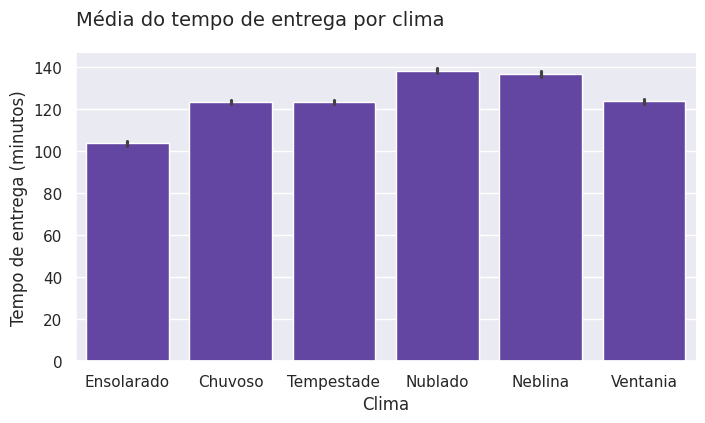

Figure(640x480)


<Figure size 640x480 with 0 Axes>

In [35]:
resposta_grafico = gerar_grafico.invoke("Crie um gráfico da média do tempo de entrega por clima.")
print(resposta_grafico)

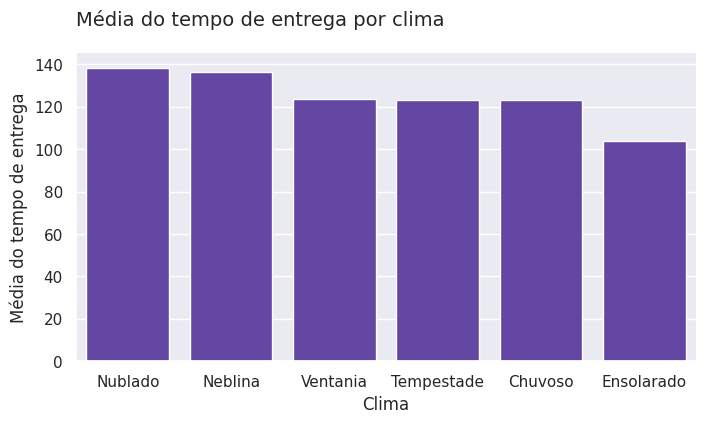

Figure(640x480)


<Figure size 640x480 with 0 Axes>

In [36]:
resposta_grafico_1 = gerar_grafico.invoke("""Crie um gráfico da média do tempo de entrega por clima.
                                             Ordene do maior para o menor valor.""")
print(resposta_grafico_1)

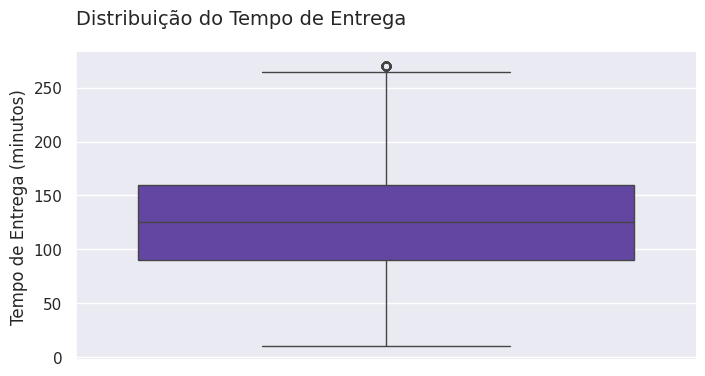

Figure(640x480)


<Figure size 640x480 with 0 Axes>

In [37]:
resposta_grafico_2 = gerar_grafico.invoke("""Plote um boxplot do tempo de entrega.""")
print(resposta_grafico_2)

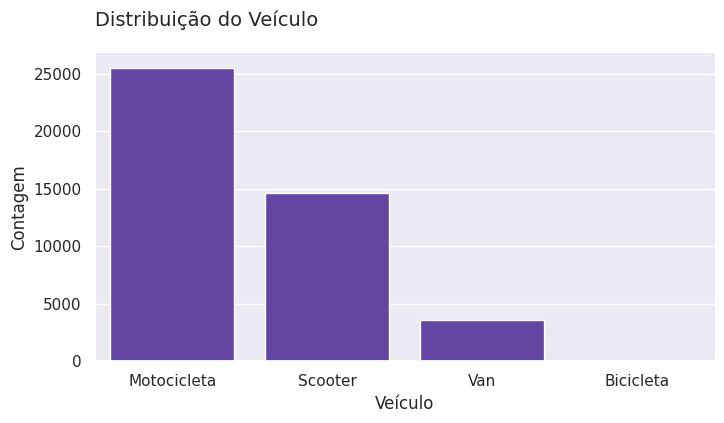

Figure(640x480)


<Figure size 640x480 with 0 Axes>

In [38]:
resposta_grafico_3 = gerar_grafico.invoke("""Crie um gráfico de distribuição do veículo""")
print(resposta_grafico_3)

<string>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:9: UserWarning: The palette list has more values (7) than needed (6), which may not be intended.


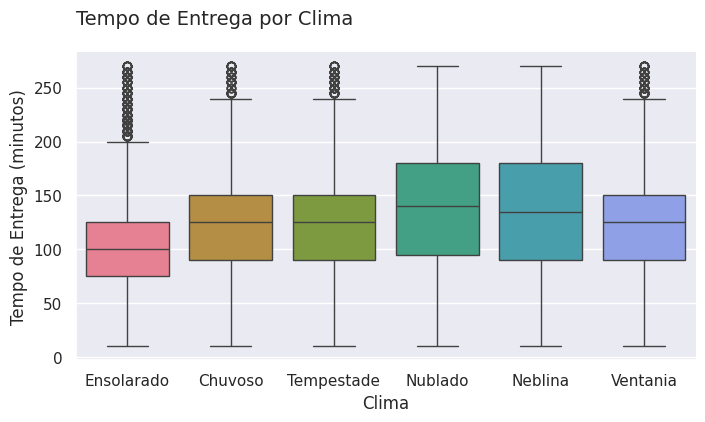

Figure(640x480)


<Figure size 640x480 with 0 Axes>

In [39]:
resposta_grafico_4 = gerar_grafico.invoke("""Plote um boxplot do tempo de entrega para cada tipo de clima.
                                             Adicione uma paleta de cores categórica.""")
print(resposta_grafico_4)

##**Aula 4: Orquestrando agentes capazes de usar múltiplas ferramentas**

In [56]:
python_tool = PythonAstREPLTool(
    locals={"df": df}
)

In [57]:
tools = [
    informacoes_dataframe,
    resumo_estatistico,
    gerar_grafico,
    python_tool,
]

###**Orientando o agente com um prompt estratégico**

In [58]:
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """Você é um assistente que utiliza ferramentas para responder perguntas."""
    ),
    ("human", "{input}"),
    ("placeholder", "{agent_scratchpad}")
])

In [59]:
df_head = df.head().to_markdown()

prompt_react_pt = PromptTemplate(
    input_variables=["input", "agent_scratchpad", "tools", "tool_names"],
    partial_variables={"df_head": df_head},
    template = """
        Você é um assistente que sempre responde em português.

        Você tem acesso a um dataframe pandas chamado `df`.
        Aqui estão as primeiras linhas do DataFrame, obtidas com `df.head().to_markdown()`:

        {df_head}

        Responda às seguintes perguntas da melhor forma possível.

        Para isso, você tem acesso às seguintes ferramentas:

        {tools}

        Use o seguinte formato:

        Question: a pergunta de entrada que você deve responder
        Thought: você deve sempre pensar no que fazer
        Action: a ação a ser tomada, deve ser uma das [{tool_names}]
        Action Input: a entrada para a ação
        Observation: o resultado da ação
        ... (este Thought/Action/Action Input/Observation pode se repetir N vezes)
        Thought: Agora eu sei a resposta final
        Final Answer: a resposta final para a pergunta de entrada original.

        Comece!

        Question: {input}
        Thought: {agent_scratchpad}"""
)

###**Criando e testando o agente**

In [60]:
pip install langchain-classic

In [61]:
from langchain_classic.agents import create_react_agent, AgentExecutor

In [62]:
agente = create_react_agent(llm=llm, tools=tools, prompt=prompt_react_pt)

orquestrador = AgentExecutor(agent=agente, tools=tools, verbose=True, handle_parsing_errors=True)

In [64]:
resposta = orquestrador.invoke({"input": "Gostaria de um relatório com informações sobre o dataframe"})
display(Markdown(resposta["output"]))



> Entering new AgentExecutor chain...
Para fornecer um relatório com informações sobre o dataframe, precisamos saber detalhes como o número de linhas e colunas, os nomes das colunas, os tipos de dados em cada coluna, a contagem de dados nulos e duplicados. Isso pode ser obtido utilizando a ferramenta "Informações DataFrame".

Action: Informações DataFrame
Action Input: Qual é o número de linhas e colunas, nomes das colunas e seus tipos de dados, contagem de dados nulos e duplicados no dataframe?## Relatório de informações gerais sobre o dataset

O DataFrame em questão possui uma dimensão total de 43.739 linhas e 16 colunas. Abaixo, segue uma descrição detalhada de cada coluna, incluindo seu nome, tipo de dado e uma breve explicação sobre o que cada coluna representa:

- **ID_pedido**: Objeto, identificador único para cada pedido.
- **anos_experiencia_agente**: Inteiro de 64 bits, representa a experiência do agente em anos.
- **classificacao_agente**: Ponto flutuante de 64 bits, class

## Relatório de informações gerais sobre o dataset

O DataFrame em questão possui uma dimensão total de 43.739 linhas e 16 colunas. Abaixo, segue uma descrição detalhada de cada coluna, incluindo seu nome, tipo de dado e uma breve explicação sobre o que cada coluna representa:

- **ID_pedido**: Objeto, identificador único para cada pedido.
- **anos_experiencia_agente**: Inteiro de 64 bits, representa a experiência do agente em anos.
- **classificacao_agente**: Ponto flutuante de 64 bits, classificação do agente.
- **latitude_loja**: Ponto flutuante de 64 bits, latitude da loja.
- **longitude_loja**: Ponto flutuante de 64 bits, longitude da loja.
- **latitude_entrega**: Ponto flutuante de 64 bits, latitude do local de entrega.
- **longitude_entrega**: Ponto flutuante de 64 bits, longitude do local de entrega.
- **data_pedido**: Objeto, data em que o pedido foi realizado.
- **hora_pedido**: Objeto, hora em que o pedido foi realizado.
- **hora_retirada**: Objeto, hora em que o pedido foi retirado.
- **clima**: Objeto, condições climáticas durante o pedido.
- **trafego**: Objeto, condições de tráfego durante o pedido.
- **veiculo**: Objeto, veículo utilizado para a entrega.
- **area**: Objeto, área de entrega.
- **categoria_produto**: Objeto, categoria do produto pedido.
- **tempo_entrega**: Inteiro de 64 bits, tempo necessário para a entrega.

Quanto aos dados nulos, observamos que:
- A coluna **classificacao_agente** contém 54 valores nulos.
- As colunas **clima** e **trafego** contêm 91 valores nulos cada.

Já em relação às strings 'nan' (em qualquer capitalização), temos:
- A coluna **hora_pedido** contém 91 ocorrências.

Não há linhas duplicadas no DataFrame, o que indica que todos os registros são únicos.

Com esses dados, podemos realizar análises interessantes, como a relação entre a experiência do agente e o tempo de entrega, ou como as condições climáticas e de tráfego afetam o tempo de entrega. Além disso, podemos explorar a distribuição geográfica dos pedidos e como diferentes categorias de produtos influenciam o tempo de entrega. Essas análises podem oferecer insights valiosos para otimizar os processos de entrega e melhorar a satisfação do cliente.

Para tratar os dados, podemos começar preenchendo os valores nulos de **classificacao_agente** com a média ou mediana da coluna, dependendo da distribuição dos dados. Para as colunas **clima** e **trafego**, podemos considerar remover as linhas com valores nulos se essas informações forem cruciais para as análises, ou então, tentar imputar esses valores com base em dados históricos ou padrões observados. A presença de strings 'nan' na coluna **hora_pedido** sugere a necessidade de uma limpeza dos dados para garantir que todas as horas estejam em um formato consistente e sem erros de digitação. Além disso, a normalização ou padronização de variáveis como **latitude_loja**, **longitude_loja**, **latitude_entrega**, e **longitude_entrega** pode ser útil para análises que envolvam cálculos de distância ou localização geográfica.

In [65]:
resposta_2 = orquestrador.invoke({"input": "Quero saber as estatísticas descritivas dos dados"})
display(Markdown(resposta_2["output"]))



> Entering new AgentExecutor chain...
Para obter as estatísticas descritivas dos dados, é necessário utilizar a ferramenta "Resumo Estatístico" com uma pergunta que solicite um resumo estatístico completo e descritivo da base de dados.

Action: Resumo Estatístico
Action Input: Quero saber as estatísticas descritivas dos dados## Relatório de estatísticas descritivas

O relatório de estatísticas descritivas apresenta uma visão geral das características dos dados coletados, fornecendo informações valiosas sobre as tendências centrais, dispersão e distribuição dos valores nas diferentes colunas. As estatísticas descritivas incluem a contagem de observações, média, desvio padrão, mínimo, 25º percentil, mediana (50º percentil), 75º percentil e máximo para cada uma das variáveis numéricas.

As colunas numéricas apresentadas incluem anos de experiência do agente, classificação do agente, latitude e longitude da loja, latitude e longitude da entrega, e tempo de entrega. Em geral, as estatísti

## Relatório de estatísticas descritivas

O relatório de estatísticas descritivas apresenta uma visão geral das características dos dados coletados, fornecendo informações valiosas sobre as tendências centrais, dispersão e distribuição dos valores nas diferentes colunas. As estatísticas descritivas incluem a contagem de observações, média, desvio padrão, mínimo, 25º percentil, mediana (50º percentil), 75º percentil e máximo para cada uma das variáveis numéricas.

As colunas numéricas apresentadas incluem anos de experiência do agente, classificação do agente, latitude e longitude da loja, latitude e longitude da entrega, e tempo de entrega. Em geral, as estatísticas descritivas sugerem que os dados apresentam uma distribuição razoavelmente simétrica, com algumas variações significativas entre as médias e os valores extremos.

A coluna "anos_experiencia_agente" apresenta uma média de 12,11 anos, com um desvio padrão de 3,11 anos, indicando que a maioria dos agentes tem entre 9 e 15 anos de experiência. A classificação do agente tem uma média de 4,63, com um desvio padrão de 0,33, sugerindo que a maioria dos agentes tem uma classificação próxima ao máximo de 5.

As coordenadas geográficas (latitude e longitude) da loja e da entrega apresentam uma grande variação, com valores mínimo e máximo que indicam uma ampla distribuição geográfica. A latitude da loja varia de -30,90 a 30,91, enquanto a longitude varia de -88,37 a 88,43. Já a latitude da entrega varia de 0,01 a 31,05, e a longitude da entrega varia de 0,01 a 88,56.

O tempo de entrega tem uma média de 124,91 minutos, com um desvio padrão de 51,92 minutos, indicando que a maioria dos pedidos leva entre 90 e 160 minutos para ser entregue.

Com base nos valores mínimo e máximo, é possível identificar possíveis outliers em algumas colunas. Por exemplo, a latitude e longitude da entrega apresentam valores muito baixos (0,01), o que pode indicar erros de digitação ou valores inválidos. Além disso, o tempo de entrega máximo de 270 minutos pode ser considerado um outlier, pois é significativamente maior do que a média e o 75º percentil.

Com base nos padrões identificados, é recomendável realizar os seguintes próximos passos na análise:

* Verificar a consistência dos dados e corrigir possíveis erros de digitação ou valores inválidos;
* Realizar uma análise de correlação entre as variáveis para identificar possíveis relações entre elas;
* Utilizar técnicas de visualização de dados para melhor entender a distribuição geográfica das lojas e entregas;
* Realizar uma análise de regressão para identificar os fatores que influenciam o tempo de entrega;
* Considerar a exclusão de outliers ou a utilização de técnicas de robustez para minimizar o impacto de valores extremos na análise.



> Entering new AgentExecutor chain...
Para criar um gráfico da média do tempo de entrega por clima, primeiro precisamos calcular a média do tempo de entrega para cada clima. Em seguida, podemos ordenar esses valores do maior para o menor e, finalmente, criar o gráfico.

Action: python_repl_ast
Action Input:
```python
import pandas as pd
import matplotlib.pyplot as plt

# Calcula a média do tempo de entrega por clima
media_tempo_entrega_por_clima = df.groupby('clima')['tempo_entrega'].mean().reset_index()

# Ordena do maior para o menor valor
media_tempo_entrega_por_clima = media_tempo_entrega_por_clima.sort_values(by='tempo_entrega', ascending=False)

print(media_tempo_entrega_por_clima)
```        clima  tempo_entrega
3     Nublado     138.286773
2     Neblina     136.570833
5    Ventania     123.658037
4  Tempestade     123.238509
0     Chuvoso     123.211825
1  Ensolarado     103.664453
Agora que temos a média do tempo de entrega por clima ordenada do maior para o menor valor, pod

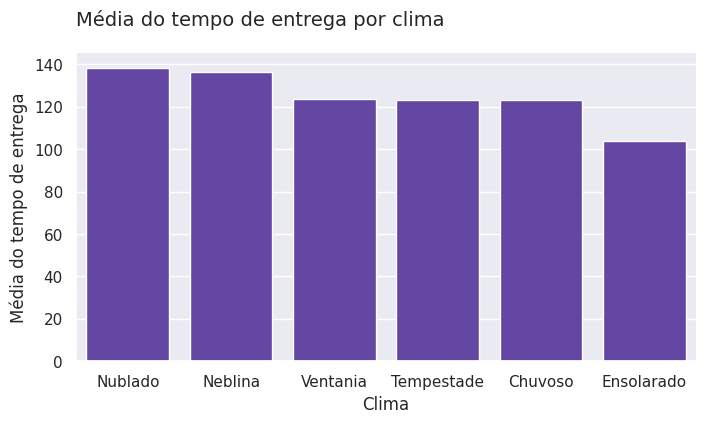

Figure(640x480)


> Finished chain.


{'input': 'Crie um gráfico da média do tempo de entrega por clima. Ordene do maior para o menor valor.',
 'output': <Figure size 640x480 with 0 Axes>}

<Figure size 640x480 with 0 Axes>

In [66]:
orquestrador.invoke({"input": "Crie um gráfico da média do tempo de entrega por clima. Ordene do maior para o menor valor."})

In [70]:
orquestrador.invoke({"input": "Qual é a média do tempo de entrega?"})



> Entering new AgentExecutor chain...


RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `llama-3.3-70b-versatile` in organization `org_01kwwfjtnte3zbb9d23fghpxmr` service tier `on_demand` on tokens per day (TPD): Limit 100000, Used 97994, Requested 2652. Please try again in 9m18.144s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}